In [1]:
from src.mesh_setup import generate_mesh
meshes = []
mesh_sizes = [1/8, 1/16, 1/32, 1/64, 1/128]
for mesh_size in mesh_sizes:
    meshes.append(generate_mesh(mesh_size))

Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (Line)
Info    : [ 30%] Meshing curve 2 (Line)
Info    : [ 60%] Meshing curve 3 (Line)
Info    : [ 80%] Meshing curve 4 (Line)
Info    : Done meshing 1D (Wall 0.000191921s, CPU 0.000131s)
Info    : Meshing 2D...
Info    : Meshing surface 1 (Plane, Frontal-Delaunay)
Info    : Done meshing 2D (Wall 0.00307226s, CPU 0.003483s)
Info    : 98 nodes 198 elements
Info    : Done generating mesh
Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (Line)
Info    : [ 30%] Meshing curve 2 (Line)
Info    : [ 60%] Meshing curve 3 (Line)
Info    : [ 80%] Meshing curve 4 (Line)
Info    : Done meshing 1D (Wall 0.000193133s, CPU 0.000194s)
Info    : Meshing 2D...
Info    : Meshing surface 1 (Plane, Frontal-Delaunay)
Info    : Done meshing 2D (Wall 0.00822074s, CPU 0.008167s)
Info    : 338 nodes 678 elements
Info    : Done generating mesh
Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (Line)
Info    : [ 30%] Meshing curve 2 (Line)
Inf

In [2]:
import ufl
from dolfinx import fem, mesh as dmesh
from petsc4py import PETSc

def u_exact(x):
    # From the streamfunction psi = sin(pi x) sin(pi y), so exactly divergence-free
    return ufl.as_vector((ufl.pi * ufl.sin(ufl.pi * x[0]) * ufl.cos(ufl.pi * x[1]),
                          -ufl.pi * ufl.cos(ufl.pi * x[0]) * ufl.sin(ufl.pi * x[1])))

def p_exact(x):
    # Zero mean on the unit square
    return ufl.cos(ufl.pi * x[0]) * ufl.cos(ufl.pi * x[1])


def setup_mms_problem(mesh, v_degree=2, q_degree=1, mu=1.0):
    V = fem.functionspace(mesh, ("Lagrange", v_degree, (2,)))
    Q = fem.functionspace(mesh, ("Lagrange", q_degree))
    u, v = ufl.TrialFunction(V), ufl.TestFunction(V)
    p, q = ufl.TrialFunction(Q), ufl.TestFunction(Q)

    # Manufactured body force f = -mu*Laplace(u) + grad(p)
    x = ufl.SpatialCoordinate(mesh)
    u_ex = u_exact(x)
    p_ex = p_exact(x)
    mu_c = fem.Constant(mesh, PETSc.ScalarType(mu))
    f = -mu_c * ufl.div(ufl.grad(u_ex)) + ufl.grad(p_ex)

    # Same weak form as your code, with mu added
    a00 = mu_c * ufl.inner(ufl.grad(u), ufl.grad(v)) * ufl.dx
    a01 = -p * ufl.div(v) * ufl.dx
    a10 = -q * ufl.div(u) * ufl.dx
    a = [[a00, a01], [a10, None]]
    L = [ufl.inner(f, v) * ufl.dx,
         fem.Constant(mesh, PETSc.ScalarType(0)) * q * ufl.dx]

    # u = u_exact on all exterior facets
    fdim = mesh.topology.dim - 1
    mesh.topology.create_connectivity(fdim, mesh.topology.dim)
    facets = dmesh.exterior_facet_indices(mesh.topology)
    dofs = fem.locate_dofs_topological(V, fdim, facets)
    u_bc = fem.Function(V)
    u_bc.interpolate(fem.Expression(u_ex, V.element.interpolation_points))
    bcs = [fem.dirichletbc(u_bc, dofs)]

    return a, L, bcs, u_ex, p_ex

In [3]:
import numpy as np
from mpi4py import MPI

def compute_errors(u_h, p_h, u_ex, p_ex, quadrature_degree=8):
    mesh = u_h.function_space.mesh
    dx = ufl.dx(domain=mesh, metadata={"quadrature_degree": quadrature_degree})

    def integrate(expr):
        return mesh.comm.allreduce(fem.assemble_scalar(fem.form(expr * dx)), op=MPI.SUM)

    # Pressure is only defined up to a constant: remove both means
    area = integrate(fem.Constant(mesh, PETSc.ScalarType(1.0)))
    p_h_mean = fem.Constant(mesh, PETSc.ScalarType(integrate(p_h) / area))
    p_ex_mean = fem.Constant(mesh, PETSc.ScalarType(integrate(p_ex) / area))

    e_u = u_h - u_ex
    e_p = (p_h - p_h_mean) - (p_ex - p_ex_mean)

    return {
        "u_L2": np.sqrt(integrate(ufl.inner(e_u, e_u))),
        "u_H1": np.sqrt(integrate(ufl.inner(ufl.grad(e_u), ufl.grad(e_u)))),
        "p_L2": np.sqrt(integrate(e_p * e_p)),
        "div_L2": np.sqrt(integrate(ufl.div(u_h) ** 2)),
    }

In [7]:
from dolfinx.fem.petsc import LinearProblem

errors_list = []
dofs = []

for i, mesh_data in enumerate(meshes):
    a, L, bcs, u_ex, p_ex = setup_mms_problem(mesh_data.mesh)
    problem = LinearProblem(
        a, L, bcs=bcs,
        kind="mpi",
        petsc_options_prefix=f"mms_{i}_",
        petsc_options={
            "ksp_type": "preonly",
            "pc_type": "lu",
            "pc_factor_mat_solver_type": "mumps",
            "mat_mumps_icntl_24": 1,   # detect the null pivot (pressure constant)
            "mat_mumps_icntl_25": 0,   # return one solution from the null space
            "ksp_error_if_not_converged": True,
        },
    )
    u_sol, p_sol = problem.solve()
    errors_list.append(compute_errors(u_sol, p_sol, u_ex, p_ex))
    dofs.append(problem.A.getSize()[0])

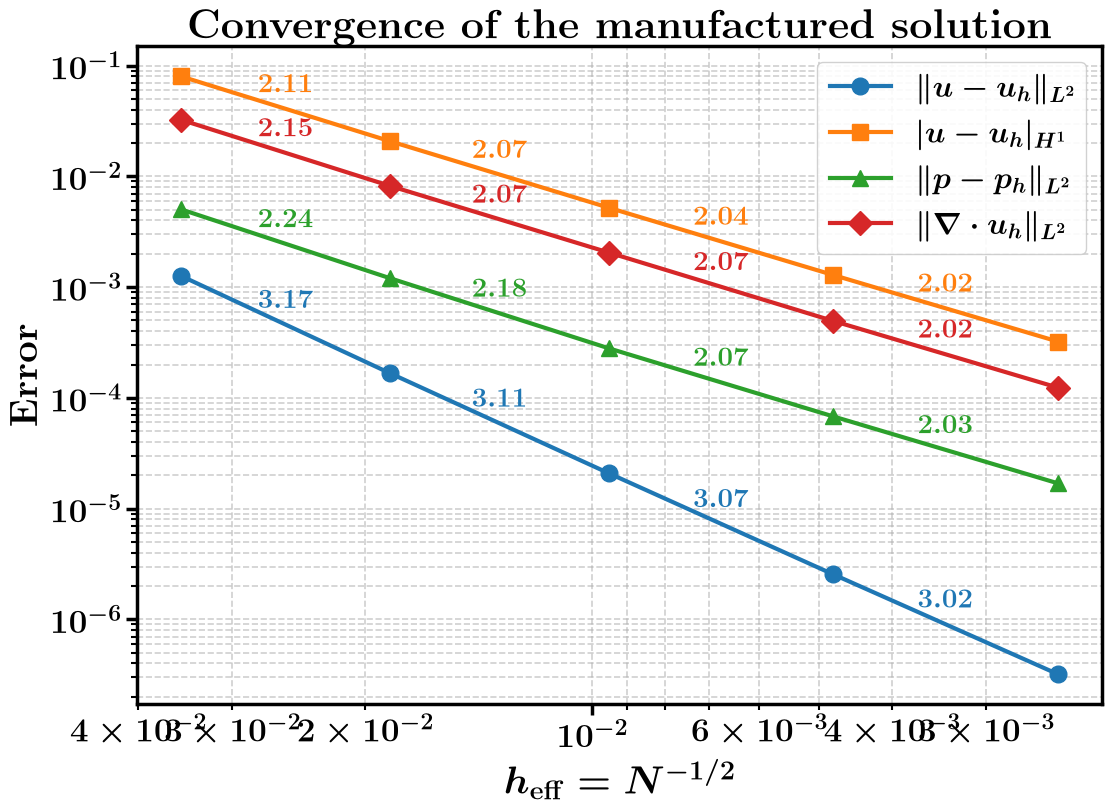

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from src.plot_style import apply_style, annotate_slopes, save
apply_style()

h_eff = np.array([n**(-1/2) for n in dofs])
series = {
    "u_L2":   (r"$\|u - u_h\|_{L^2}$",         "tab:blue",   "o"),
    "u_H1":   (r"$|u - u_h|_{H^1}$",           "tab:orange", "s"),
    "p_L2":   (r"$\|p - p_h\|_{L^2}$",         "tab:green",  "^"),
    "div_L2": (r"$\|\nabla\cdot u_h\|_{L^2}$", "tab:red",    "D"),
}

fig, ax = plt.subplots(figsize=(11, 8), constrained_layout=True)
for key, (label, color, marker) in series.items():
    err = np.array([e[key] for e in errors_list])
    ax.loglog(h_eff, err, marker=marker, color=color, label=label)
    annotate_slopes(ax, h_eff, err, color)
ax.invert_xaxis()
ax.set_xlabel(r"$h_\mathrm{eff} = N^{-1/2}$")
ax.set_ylabel(r"\textbf{Error}")
ax.set_title(r"\textbf{Convergence of the manufactured solution}")
ax.legend()
save(fig, "errors.png")
plt.show()